# CNN Binary Classification

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import Sequence
from tensorflow.keras.metrics import Precision, Recall, TruePositives, FalsePositives, TrueNegatives, FalseNegatives
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, f1_score, precision_score, recall_score, accuracy_score
from skimage.transform import resize
from tensorflow.keras.preprocessing.image import img_to_array

class CustomDataGenerator(Sequence):
    def __init__(self, data_paths, labels, batch_size=512, shuffle=True, target_size=(256, 256)):
        self.data_paths = data_paths
        self.labels = labels
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.target_size = target_size
        self.on_epoch_end()

    def __load_dicom(self, path):
        try:
            dicom = pydicom.dcmread(path, force=True)
            image = dicom.pixel_array
            image = resize(image, self.target_size, mode='constant', anti_aliasing=True)
            image = img_to_array(image)
            return image
        except Exception as e:
            print(f"Error reading {path}: {e}")
            return np.zeros((*self.target_size, 1))  # Return a zero array to maintain array shape

    def __data_generation(self, paths):
        batch_images = np.empty((len(paths), *self.target_size, 1))
        batch_labels = np.empty((len(paths),), dtype=int)

        for i, path in enumerate(paths):
            image = self.__load_dicom(path)
            batch_images[i,] = image
            batch_labels[i] = self.labels[self.data_paths.index(path)]

        return batch_images, batch_labels

    def on_epoch_end(self):
        if self.shuffle:
            data = list(zip(self.data_paths, self.labels))
            np.random.shuffle(data)
            self.data_paths, self.labels = zip(*data)

    def __len__(self):
        return int(np.floor(len(self.data_paths) / self.batch_size))

    def __getitem__(self, index):
        start = index * self.batch_size
        end = (index + 1) * self.batch_size
        paths = self.data_paths[start:end]
        X, y = self.__data_generation(paths)
        return X, y

def load_dataset(dataset_dir):
    data_paths = []
    labels = []
    classes = {'CN': 0, 'MCI': 1}  # Modify as needed
    for class_dir in os.listdir(dataset_dir):
        class_path = os.path.join(dataset_dir, class_dir)
        for patient_id in os.listdir(class_path):
            patient_path = os.path.join(class_path, patient_id)
            for image_filename in os.listdir(patient_path):
                data_paths.append(os.path.join(patient_path, image_filename))
                labels.append(classes[class_dir])
    return data_paths, labels

def build_model(input_shape):
    model = Sequential([
        Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        MaxPooling2D(2, 2),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D(2, 2),
        Conv2D(128, (3, 3), activation='relu'),
        MaxPooling2D(2, 2),
        Flatten(),
        Dense(512, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy', Precision(), Recall()])
    return model

dataset_dir = r'G:\master 2\mci and nc finale'
data_paths, labels = load_dataset(dataset_dir)

train_paths, val_paths, train_labels, val_labels = train_test_split(data_paths, labels, test_size=0.2, random_state=42)

train_generator = CustomDataGenerator(train_paths, train_labels, batch_size=512, target_size=(128, 128))
val_generator = CustomDataGenerator(val_paths, val_labels, batch_size=512, target_size=(128, 128))

model = build_model((128, 128, 1))
history = model.fit(train_generator, validation_data=val_generator, epochs=10)

# Evaluate the model on the full validation dataset
val_y = []
val_pred = []
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]
    y_pred_batch = model.predict(X_batch)
    val_y.extend(y_batch)
    val_pred.extend(y_pred_batch)

val_y = np.array(val_y)
val_pred = np.array(val_pred)

# Calculate metrics
accuracy = accuracy_score(val_y, np.round(val_pred))
precision = precision_score(val_y, np.round(val_pred))
recall = recall_score(val_y, np.round(val_pred))
f1 = f1_score(val_y, np.round(val_pred))
fpr, tpr, _ = roc_curve(val_y, val_pred)
roc_auc = auc(fpr, tpr)

# Print metrics
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")
print(f"AUC: {roc_auc}")

# Plot ROC Curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()


Epoch 1/10
735/735 [==============================] - 14175s 19s/step - loss: 0.3341 - accuracy: 0.8501 - precision_2: 0.8528 - recall_2: 0.8266 - val_loss: 0.1992 - val_accuracy: 0.9215 - val_precision_2: 0.9414 - val_recall_2: 0.8904
Epoch 2/10
735/735 [==============================] - 7340s 10s/step - loss: 0.1739 - accuracy: 0.9297 - precision_2: 0.9340 - recall_2: 0.9164 - val_loss: 0.1257 - val_accuracy: 0.9492 - val_precision_2: 0.9476 - val_recall_2: 0.9454
Epoch 3/10
735/735 [==============================] - 12729s 17s/step - loss: 0.1101 - accuracy: 0.9564 - precision_2: 0.9579 - recall_2: 0.9498 - val_loss: 0.0813 - val_accuracy: 0.9684 - val_precision_2: 0.9758 - val_recall_2: 0.9572
Epoch 4/10
735/735 [==============================] - 7177s 10s/step - loss: 0.0728 - accuracy: 0.9716 - precision_2: 0.9727 - recall_2: 0.9673 - val_loss: 0.0511 - val_accuracy: 0.9807 - val_precision_2: 0.9862 - val_recall_2: 0.9730
Epoch 5/10
735/735 [==============================] - 6875

# CNN Multi Class Classification

In [2]:
pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ---------------------------------------- 0.0/162.8 kB ? eta -:--:--
     -- ------------------------------------- 10.2/162.8 kB ? eta -:--:--
     ------------------ ------------------ 81.9/162.8 kB 907.3 kB/s eta 0:00:01
     -------------------------------------- 162.8/162.8 kB 1.4 MB/s eta 0:00:00
  Using cached pyparsing-3.1.2-py3-none-any.whl.metadata (5.1 kB)
   ---------------------------------------- 0.0/8.0 MB ? eta -:--:--
    --------------------------------------- 0.2/8.0 MB 11.5 MB/s eta 0:00:01
   -- ------------------------------------- 0.5/8.0 MB 5.9 MB/s eta 0:00:02
   ----- ---------------------------------- 1.1/8.0 MB 8.7 MB/s eta 0:00:01
   ----------- ---------------------------- 2.3/8.0 MB 13.3 MB/s eta 0:00:01
   ---------------------- ----------------- 4.5/8.0 MB 20.7 MB/s eta 0:00:01
   ------------------------------ --------- 6.0/8.0 MB 25.4 MB/s eta 0:00:01
   ------------------------------ 

Epoch 1/10
750/750 [==============================] - 13199s 18s/step - loss: 0.9700 - categorical_accuracy: 0.5046 - precision_2: 0.6162 - recall_2: 0.2315 - val_loss: 0.8714 - val_categorical_accuracy: 0.5813 - val_precision_2: 0.6678 - val_recall_2: 0.3910
Epoch 2/10
750/750 [==============================] - 13435s 18s/step - loss: 0.8045 - categorical_accuracy: 0.6226 - precision_2: 0.6964 - recall_2: 0.4848 - val_loss: 0.6649 - val_categorical_accuracy: 0.7116 - val_precision_2: 0.7832 - val_recall_2: 0.5990
Epoch 3/10
750/750 [==============================] - 12105s 16s/step - loss: 0.6334 - categorical_accuracy: 0.7170 - precision_2: 0.7715 - recall_2: 0.6391 - val_loss: 0.4937 - val_categorical_accuracy: 0.7967 - val_precision_2: 0.8444 - val_recall_2: 0.7384
Epoch 4/10
750/750 [==============================] - 11851s 16s/step - loss: 0.5046 - categorical_accuracy: 0.7805 - precision_2: 0.8215 - recall_2: 0.7305 - val_loss: 0.3852 - val_categorical_accuracy: 0.8508 - val_pre

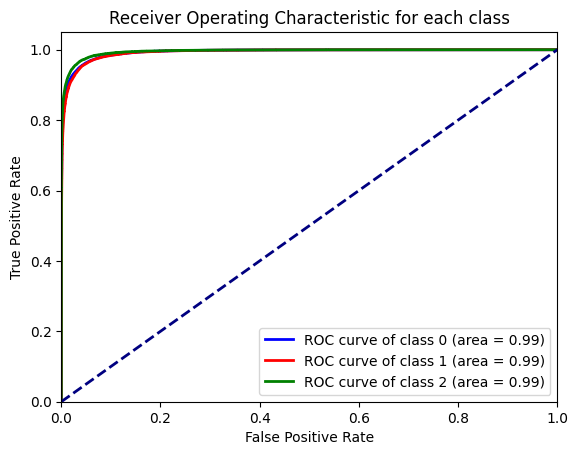

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import Sequence, to_categorical
from tensorflow.keras.metrics import CategoricalAccuracy, Precision, Recall
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, precision_score, recall_score, f1_score, roc_auc_score
from skimage.transform import resize
from tensorflow.keras.preprocessing.image import img_to_array
from itertools import cycle

class CustomDataGenerator(Sequence):
    def __init__(self, data_paths, labels, batch_size=32, shuffle=True, target_size=(256, 256)):
        self.data_paths = data_paths
        self.labels = labels
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.target_size = target_size
        self.on_epoch_end()

    def __load_dicom(self, path):
        try:
            dicom = pydicom.dcmread(path, force=True)
            image = dicom.pixel_array
            image = resize(image, self.target_size, mode='constant', anti_aliasing=True)
            image = img_to_array(image)
            return image
        except Exception as e:
            print(f"Error reading {path}: {e}")
            return np.zeros((*self.target_size, 1))  # Return a zero array to maintain array shape

    def __data_generation(self, paths):
        batch_images = np.empty((len(paths), *self.target_size, 1))
        batch_labels = np.empty((len(paths), len(np.unique(self.labels))), dtype=int)

        for i, path in enumerate(paths):
            image = self.__load_dicom(path)
            batch_images[i,] = image
            batch_labels[i,] = to_categorical(self.labels[self.data_paths.index(path)], num_classes=len(np.unique(self.labels)))

        return batch_images, batch_labels

    def on_epoch_end(self):
        if self.shuffle:
            data = list(zip(self.data_paths, self.labels))
            np.random.shuffle(data)
            self.data_paths, self.labels = zip(*data)

    def __len__(self):
        return int(np.floor(len(self.data_paths) / self.batch_size))

    def __getitem__(self, index):
        start = index * self.batch_size
        end = (index + 1) * self.batch_size
        paths = self.data_paths[start:end]
        X, y = self.__data_generation(paths)
        return X, y

def load_dataset(dataset_dir):
    data_paths = []
    labels = []
    classes = {'CN': 0, 'MCI': 1, 'AD': 2}
    for class_dir in os.listdir(dataset_dir):
        class_path = os.path.join(dataset_dir, class_dir)
        for patient_id in os.listdir(class_path):
            patient_path = os.path.join(class_path, patient_id)
            for image_filename in os.listdir(patient_path):
                data_paths.append(os.path.join(patient_path, image_filename))
                labels.append(classes[class_dir])
    return data_paths, labels

def build_model(input_shape, num_classes):
    model = Sequential([
        Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        MaxPooling2D(2, 2),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D(2, 2),
        Conv2D(128, (3, 3), activation='relu'),
        MaxPooling2D(2, 2),
        Flatten(),
        Dense(512, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=[CategoricalAccuracy(), Precision(), Recall()])
    return model

# Configuration
dataset_dir = r'G:\NEW DATASET'
data_paths, labels = load_dataset(dataset_dir)
train_paths, val_paths, train_labels, val_labels = train_test_split(data_paths, labels, test_size=0.2, random_state=42)
num_classes = len(np.unique(labels))
train_generator = CustomDataGenerator(train_paths, train_labels, batch_size=512, target_size=(160, 160))
val_generator = CustomDataGenerator(val_paths, val_labels, batch_size=512, target_size=(160, 160))

# Build and train the model
model = build_model((160, 160, 1), num_classes)
history = model.fit(train_generator, validation_data=val_generator, epochs=10)

# Evaluate and plot ROC curve for each class
val_y = []
val_pred = []
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]
    y_pred_batch = model.predict(X_batch)
    val_y.extend(y_batch)
    val_pred.extend(y_pred_batch)

val_y = np.array(val_y)
val_pred = np.array(val_pred)

# Compute ROC AUC for each class
roc_aucs = roc_auc_score(val_y, val_pred, multi_class='ovr', average=None)

# Compute Precision, Recall, and F1 Score for each class
precisions = precision_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
recalls = recall_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
f1_scores = f1_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)

print("Precision per class:", precisions)
print("Recall per class:", recalls)
print("F1 Score per class:", f1_scores)
print("AUC per class:", roc_aucs)

# You might also want to print average metrics
print("Average Precision:", np.mean(precisions))
print("Average Recall:", np.mean(recalls))
print("Average F1 Score:", np.mean(f1_scores))
print("Average AUC:", np.mean(roc_aucs))

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
colors = cycle(['blue', 'red', 'green'])
for i, color in enumerate(colors):
    if i >= num_classes:
        break
    fpr[i], tpr[i], _ = roc_curve(val_y[:, i], val_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

    plt.plot(fpr[i], tpr[i], color=color, lw=2, label=f'ROC curve of class {i} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic for each class')
plt.legend(loc="lower right")
plt.show()

In [6]:
val_y = []
val_pred = []
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]
    y_pred_batch = model.predict(X_batch)
    val_y.extend(y_batch)
    val_pred.extend(y_pred_batch)

val_y = np.array(val_y)
val_pred = np.array(val_pred)

# Compute metrics for each class
precisions = precision_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
recalls = recall_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
f1_scores = f1_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
roc_aucs = roc_auc_score(val_y, val_pred, multi_class='ovr', average=None)

# Compute specificity for each class
specificities = []
for i in range(len(precisions)):
    tn = ((val_y.argmax(axis=1) != i) & (val_pred.argmax(axis=1) != i)).sum()
    fp = ((val_y.argmax(axis=1) != i) & (val_pred.argmax(axis=1) == i)).sum()
    specificity = tn / (tn + fp)
    specificities.append(specificity)

# Display the best values among the metrics
best_precision = max(precisions)    
best_recall = max(recalls)
best_f1_score = max(f1_scores)
best_roc_auc = max(roc_aucs)
best_specificity = max(specificities)

print("Best Precision:", best_precision)
print("Best Recall:", best_recall)
print("Best F1 Score:", best_f1_score)
print("Best AUC:", best_roc_auc)
print("Best Specificity:", best_specificity)

16/16 [==============================] - 0s 24ms/step
Best Precision: 0.9436759150709912
Best Recall: 0.9510594165988395
Best F1 Score: 0.9473532796317606
Best AUC: 0.9948937043451253
Best Specificity: 0.9858494263987247


In [11]:
model.save_weights(r"G:\checkpoint\after_augmentation.h5")

In [14]:
model1 = build_model((160, 160, 1), num_classes)
model1.load_weights(r"G:\checkpoint\after_augmentation.h5")     
history1 =  model1.fit(train_generator, validation_data=val_generator, epochs=3)

c:\ProgramData\anaconda3\envs\py310\lib\site-packages\pydicom\filereader.py:353: UserWarning: Expected explicit VR, but found implicit VR - using implicit VR for reading
  warnings.warn(msg + f" - using {found_vr} VR for reading", UserWarning)


Epoch 1/3
900/900 [==============================] - 18490s 21s/step - loss: 0.0890 - categorical_accuracy: 0.9656 - precision_4: 0.9683 - recall_4: 0.9633 - val_loss: 0.0637 - val_categorical_accuracy: 0.9793 - val_precision_4: 0.9810 - val_recall_4: 0.9778
Epoch 2/3
900/900 [==============================] - 16561s 18s/step - loss: 0.0822 - categorical_accuracy: 0.9686 - precision_4: 0.9709 - recall_4: 0.9664 - val_loss: 0.0641 - val_categorical_accuracy: 0.9797 - val_precision_4: 0.9816 - val_recall_4: 0.9779
Epoch 3/3
900/900 [==============================] - 18637s 21s/step - loss: 0.0768 - categorical_accuracy: 0.9709 - precision_4: 0.9729 - recall_4: 0.9690 - val_loss: 0.0621 - val_categorical_accuracy: 0.9801 - val_precision_4: 0.9820 - val_recall_4: 0.9785


In [15]:
model1.save_weights(r"G:\checkpoint\after_augmentation_adding_3_epochs.h5")

In [18]:
model2 = build_model((160, 160, 1), num_classes)
model2.load_weights(r"G:\checkpoint\after_augmentation_adding_3_epochs.h5")
history2 =  model2.fit(train_generator, validation_data=val_generator, epochs=1)

900/900 [==============================] - 19985s 22s/step - loss: 0.0724 - categorical_accuracy: 0.9724 - precision_7: 0.9743 - recall_7: 0.9708 - val_loss: 0.0538 - val_categorical_accuracy: 0.9834 - val_precision_7: 0.9849 - val_recall_7: 0.9823


In [19]:
model2.save_weights(r"G:\checkpoint\after_augmentation_adding_1_epochs.h5")

In [20]:
model3 = build_model((160, 160, 1), num_classes)
model3.load_weights(r"G:\checkpoint\after_augmentation_adding_1_epochs.h5")
history3 =  model3.fit(train_generator, validation_data=val_generator, epochs=2)

c:\ProgramData\anaconda3\envs\py310\lib\site-packages\pydicom\filereader.py:353: UserWarning: Expected explicit VR, but found implicit VR - using implicit VR for reading
  warnings.warn(msg + f" - using {found_vr} VR for reading", UserWarning)


Epoch 1/2
900/900 [==============================] - 17330s 19s/step - loss: 0.0686 - categorical_accuracy: 0.9744 - precision_8: 0.9759 - recall_8: 0.9729 - val_loss: 0.0598 - val_categorical_accuracy: 0.9812 - val_precision_8: 0.9824 - val_recall_8: 0.9798
Epoch 2/2
900/900 [==============================] - 16765s 19s/step - loss: 0.0643 - categorical_accuracy: 0.9759 - precision_8: 0.9775 - recall_8: 0.9745 - val_loss: 0.0545 - val_categorical_accuracy: 0.9841 - val_precision_8: 0.9850 - val_recall_8: 0.9834


In [21]:
model3.save_weights(r"G:\checkpoint\after_augmentation_adding_2_epochs.h5")

In [22]:
model4 = build_model((160, 160, 1), num_classes)
model4.load_weights(r"G:\checkpoint\after_augmentation_adding_2_epochs.h5")
history4 =  model4.fit(train_generator, validation_data=val_generator, epochs=4)

c:\ProgramData\anaconda3\envs\py310\lib\site-packages\pydicom\filereader.py:353: UserWarning: Expected explicit VR, but found implicit VR - using implicit VR for reading
  warnings.warn(msg + f" - using {found_vr} VR for reading", UserWarning)


Epoch 1/4
900/900 [==============================] - 17848s 20s/step - loss: 0.0619 - categorical_accuracy: 0.9769 - precision_9: 0.9782 - recall_9: 0.9757 - val_loss: 0.0526 - val_categorical_accuracy: 0.9845 - val_precision_9: 0.9853 - val_recall_9: 0.9838
Epoch 2/4
900/900 [==============================] - 16151s 18s/step - loss: 0.0588 - categorical_accuracy: 0.9785 - precision_9: 0.9797 - recall_9: 0.9773 - val_loss: 0.0521 - val_categorical_accuracy: 0.9843 - val_precision_9: 0.9854 - val_recall_9: 0.9835
Epoch 3/4
900/900 [==============================] - 16136s 18s/step - loss: 0.0564 - categorical_accuracy: 0.9792 - precision_9: 0.9803 - recall_9: 0.9782 - val_loss: 0.0484 - val_categorical_accuracy: 0.9858 - val_precision_9: 0.9866 - val_recall_9: 0.9850
Epoch 4/4
900/900 [==============================] - 16195s 18s/step - loss: 0.0539 - categorical_accuracy: 0.9799 - precision_9: 0.9810 - recall_9: 0.9790 - val_loss: 0.0476 - val_categorical_accuracy: 0.9859 - val_precisi

In [23]:
model4.save_weights(r"G:\checkpoint\after_augmentation_adding_4_epochs.h5")

In [24]:
modelfinale = build_model((160, 160, 1), num_classes)               
modelfinale.load_weights(r"G:\checkpoint\after_augmentation_adding_4_epochs.h5")
historyfinale = modelfinale.fit(train_generator, validation_data=val_generator, epochs=1)

c:\ProgramData\anaconda3\envs\py310\lib\site-packages\pydicom\filereader.py:353: UserWarning: Expected explicit VR, but found implicit VR - using implicit VR for reading
  warnings.warn(msg + f" - using {found_vr} VR for reading", UserWarning)


900/900 [==============================] - 17772s 20s/step - loss: 0.0526 - categorical_accuracy: 0.9806 - precision_10: 0.9816 - recall_10: 0.9798 - val_loss: 0.0534 - val_categorical_accuracy: 0.9855 - val_precision_10: 0.9863 - val_recall_10: 0.9850


In [25]:
modelfinale.save_weights(r"G:\checkpoint\after_augmentation_finale.h5")

In [26]:
model5 = build_model((160, 160, 1), num_classes)               
model5.load_weights(r"G:\checkpoint\after_augmentation_finale.h5")
history5 = model5.fit(train_generator, validation_data=val_generator, epochs=5)

c:\ProgramData\anaconda3\envs\py310\lib\site-packages\pydicom\filereader.py:353: UserWarning: Expected explicit VR, but found implicit VR - using implicit VR for reading
  warnings.warn(msg + f" - using {found_vr} VR for reading", UserWarning)


Epoch 1/5
900/900 [==============================] - 16850s 19s/step - loss: 0.0509 - categorical_accuracy: 0.9814 - precision_11: 0.9823 - recall_11: 0.9807 - val_loss: 0.0497 - val_categorical_accuracy: 0.9866 - val_precision_11: 0.9875 - val_recall_11: 0.9859
Epoch 2/5
900/900 [==============================] - 16135s 18s/step - loss: 0.0492 - categorical_accuracy: 0.9821 - precision_11: 0.9829 - recall_11: 0.9813 - val_loss: 0.0540 - val_categorical_accuracy: 0.9852 - val_precision_11: 0.9860 - val_recall_11: 0.9847
Epoch 3/5
900/900 [==============================] - 16634s 18s/step - loss: 0.0458 - categorical_accuracy: 0.9834 - precision_11: 0.9843 - recall_11: 0.9826 - val_loss: 0.0525 - val_categorical_accuracy: 0.9859 - val_precision_11: 0.9865 - val_recall_11: 0.9854
Epoch 4/5
900/900 [==============================] - 17863s 20s/step - loss: 0.0452 - categorical_accuracy: 0.9834 - precision_11: 0.9842 - recall_11: 0.9826 - val_loss: 0.0469 - val_categorical_accuracy: 0.9874

In [31]:
model5.save_weights(r"G:\checkpoint\after_augmentation_adding_5_before last_epochs.h5")

c:\ProgramData\anaconda3\envs\py310\lib\site-packages\pydicom\filereader.py:353: UserWarning: Expected explicit VR, but found implicit VR - using implicit VR for reading
  warnings.warn(msg + f" - using {found_vr} VR for reading", UserWarning)


16/16 [==============================] - 0s 15ms/step
Best Precision: 0.991304347826087
Best Recall: 0.9900375547673691
Best F1 Score: 0.9906705463275878
Best AUC: 0.9994858809835441
Best Specificity: 0.9956672218174248


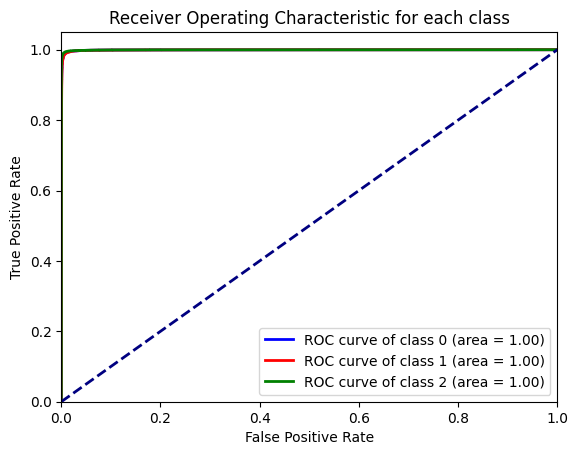

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import Sequence, to_categorical
from tensorflow.keras.metrics import CategoricalAccuracy, Precision, Recall
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, precision_score, recall_score, f1_score, roc_auc_score
from skimage.transform import resize
from tensorflow.keras.preprocessing.image import img_to_array
from itertools import cycle

class CustomDataGenerator(Sequence):
    def __init__(self, data_paths, labels, batch_size=32, shuffle=True, target_size=(256, 256)):
        self.data_paths = data_paths
        self.labels = labels
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.target_size = target_size
        self.on_epoch_end()

    def __load_dicom(self, path):
        try:
            dicom = pydicom.dcmread(path, force=True)
            image = dicom.pixel_array
            image = resize(image, self.target_size, mode='constant', anti_aliasing=True)
            image = img_to_array(image)
            return image
        except Exception as e:
            print(f"Error reading {path}: {e}")
            return np.zeros((*self.target_size, 1))  # Return a zero array to maintain array shape

    def __data_generation(self, paths):
        batch_images = np.empty((len(paths), *self.target_size, 1))
        batch_labels = np.empty((len(paths), len(np.unique(self.labels))), dtype=int)

        for i, path in enumerate(paths):
            image = self.__load_dicom(path)
            batch_images[i,] = image
            batch_labels[i,] = to_categorical(self.labels[self.data_paths.index(path)], num_classes=len(np.unique(self.labels)))

        return batch_images, batch_labels

    def on_epoch_end(self):
        if self.shuffle:
            data = list(zip(self.data_paths, self.labels))
            np.random.shuffle(data)
            self.data_paths, self.labels = zip(*data)

    def __len__(self):
        return int(np.floor(len(self.data_paths) / self.batch_size))

    def __getitem__(self, index):
        start = index * self.batch_size
        end = (index + 1) * self.batch_size
        paths = self.data_paths[start:end]
        X, y = self.__data_generation(paths)
        return X, y

def load_dataset(dataset_dir):
    data_paths = []
    labels = []
    classes = {'CN': 0, 'MCI': 1, 'AD': 2}
    for class_dir in os.listdir(dataset_dir):
        class_path = os.path.join(dataset_dir, class_dir)
        for patient_id in os.listdir(class_path):
            patient_path = os.path.join(class_path, patient_id)
            for image_filename in os.listdir(patient_path):
                data_paths.append(os.path.join(patient_path, image_filename))
                labels.append(classes[class_dir])
    return data_paths, labels

def build_model(input_shape, num_classes):
    model = Sequential([
        Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        MaxPooling2D(2, 2),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D(2, 2),
        Conv2D(128, (3, 3), activation='relu'),
        MaxPooling2D(2, 2),
        Flatten(),
        Dense(512, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=[CategoricalAccuracy(), Precision(), Recall()])
    return model

# Configuration
dataset_dir = r'G:\NEW DATASET'
data_paths, labels = load_dataset(dataset_dir)
train_paths, val_paths, train_labels, val_labels = train_test_split(data_paths, labels, test_size=0.2, random_state=42)
num_classes = len(np.unique(labels))
train_generator = CustomDataGenerator(train_paths, train_labels, batch_size=512, target_size=(160, 160))
val_generator = CustomDataGenerator(val_paths, val_labels, batch_size=512, target_size=(160, 160))

# Rebuild the model
input_shape = (160, 160, 1)  # Replace with your input shape
model5 = build_model(input_shape, num_classes)

# Load the saved weights
model5.load_weights(r"G:\checkpoint\after_augmentation_adding_5_before last_epochs.h5")

# Proceed with evaluation and metric calculations
val_y = []
val_pred = []
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]
    y_pred_batch = model5.predict(X_batch)
    val_y.extend(y_batch)
    val_pred.extend(y_pred_batch)

val_y = np.array(val_y)
val_pred = np.array(val_pred)

# Compute metrics for each class
precisions = precision_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
recalls = recall_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
f1_scores = f1_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
roc_aucs = roc_auc_score(val_y, val_pred, multi_class='ovr', average=None)

# Compute specificity for each class
specificities = []
for i in range(len(precisions)):
    tn = ((val_y.argmax(axis=1) != i) & (val_pred.argmax(axis=1) != i)).sum()
    fp = ((val_y.argmax(axis=1) != i) & (val_pred.argmax(axis=1) == i)).sum()
    specificity = tn / (tn + fp)
    specificities.append(specificity)

# Display the best values among the metrics
best_precision = max(precisions)
best_recall = max(recalls)
best_f1_score = max(f1_scores)
best_roc_auc = max(roc_aucs)
best_specificity = max(specificities)

print("Best Precision:", best_precision)
print("Best Recall:", best_recall)
print("Best F1 Score:", best_f1_score)
print("Best AUC:", best_roc_auc)
print("Best Specificity:", best_specificity)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
colors = cycle(['blue', 'red', 'green'])
for i, color in enumerate(colors):
    if i >= num_classes:
        break
    fpr[i], tpr[i], _ = roc_curve(val_y[:, i], val_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

    plt.plot(fpr[i], tpr[i], color=color, lw=2, label=f'ROC curve of class {i} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic for each class')
plt.legend(loc="lower right")
plt.show()


In [2]:
from tensorflow.keras.models import load_model

# Load the saved model
model_path = r"G:\checkpoint\after_augmentation_adding_5_before last_epochs.h5"  # Replace with the actual path to your saved model
model5 = load_model(model_path)

# Evaluate and plot ROC curve for each class
val_y = []
val_pred = []
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]
    y_pred_batch = model5.predict(X_batch)
    val_y.extend(y_batch)
    val_pred.extend(y_pred_batch)

val_y = np.array(val_y)
val_pred = np.array(val_pred)

# Compute metrics for each class
precisions = precision_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
recalls = recall_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
f1_scores = f1_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
roc_aucs = roc_auc_score(val_y, val_pred, multi_class='ovr', average=None)

# Compute specificity for each class
specificities = []
for i in range(len(precisions)):
    tn = ((val_y.argmax(axis=1) != i) & (val_pred.argmax(axis=1) != i)).sum()
    fp = ((val_y.argmax(axis=1) != i) & (val_pred.argmax(axis=1) == i)).sum()
    specificity = tn / (tn + fp)
    specificities.append(specificity)

# Display the best values among the metrics
best_precision = max(precisions)
best_recall = max(recalls)
best_f1_score = max(f1_scores)
best_roc_auc = max(roc_aucs)
best_specificity = max(specificities)

print("Best Precision:", best_precision)
print("Best Recall:", best_recall)
print("Best F1 Score:", best_f1_score)
print("Best AUC:", best_roc_auc)
print("Best Specificity:", best_specificity)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
colors = cycle(['blue', 'red', 'green'])
for i, color in enumerate(colors):
    if i >= num_classes:
        break
    fpr[i], tpr[i], _ = roc_curve(val_y[:, i], val_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

    plt.plot(fpr[i], tpr[i], color=color, lw=2, label=f'ROC curve of class {i} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic for each class')
plt.legend(loc="lower right")
plt.show()


ValueError: No model config found in the file at <tensorflow.python.platform.gfile.GFile object at 0x000001E880B72D70>.

16/16 [==============================] - 0s 13ms/step
Precision per class: [0.98768171 0.98478802 0.99130435]
Recall per class: [0.98603476 0.98768031 0.99003755]
F1 Score per class: [0.98685755 0.98623204 0.99067055]
AUC per class: [0.99925543 0.99909721 0.99948588]
Average Precision: 0.9879246908947739
Average Recall: 0.9879175411463019
Average F1 Score: 0.9879200451389667
Average AUC: 0.9992795078752724


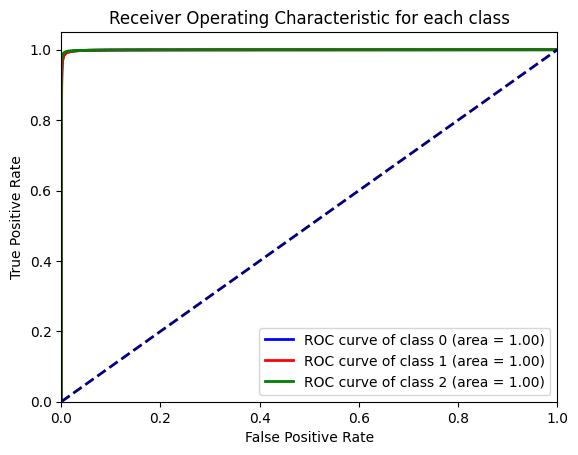

In [33]:
# Reuse the model5 for evaluation since it's the final trained model
val_y = []
val_pred = []
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]
    y_pred_batch = model5.predict(X_batch)
    val_y.extend(y_batch)
    val_pred.extend(y_pred_batch)

val_y = np.array(val_y)
val_pred = np.array(val_pred)

# Compute ROC AUC for each class
roc_aucs = roc_auc_score(val_y, val_pred, multi_class='ovr', average=None)

# Compute Precision, Recall, and F1 Score for each class
precisions = precision_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
recalls = recall_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
f1_scores = f1_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)

print("Precision per class:", precisions)
print("Recall per class:", recalls)
print("F1 Score per class:", f1_scores)
print("AUC per class:", roc_aucs)

# Print average metrics
print("Average Precision:", np.mean(precisions))
print("Average Recall:", np.mean(recalls))
print("Average F1 Score:", np.mean(f1_scores))
print("Average AUC:", np.mean(roc_aucs))

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
colors = cycle(['blue', 'red', 'green'])
for i, color in enumerate(colors):
    if i >= num_classes:
        break
    fpr[i], tpr[i], _ = roc_curve(val_y[:, i], val_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

    plt.plot(fpr[i], tpr[i], color=color, lw=2, label=f'ROC curve of class {i} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic for each class')
plt.legend(loc="lower right")
plt.show()


In [ ]:
val_y = []
val_pred = []
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]
    y_pred_batch = model5.predict(X_batch)
    val_y.extend(y_batch)
    val_pred.extend(y_pred_batch)

val_y = np.array(val_y)
val_pred = np.array(val_pred)

# Compute ROC AUC for each class
roc_aucs = roc_auc_score(val_y, val_pred, multi_class='ovr', average=None)

# Compute Precision, Recall, and F1 Score for each class
precisions = precision_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
recalls = recall_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
f1_scores = f1_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)

print("Precision per class:", precisions)
print("Recall per class:", recalls)
print("F1 Score per class:", f1_scores)
print("AUC per class:", roc_aucs)

# Print average metrics
print("Average Precision:", np.mean(precisions))
print("Average Recall:", np.mean(recalls))
print("Average F1 Score:", np.mean(f1_scores))
print("Average AUC:", np.mean(roc_aucs))

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
colors = cycle(['blue', 'red', 'green'])
for i, color in enumerate(colors):
    if i >= num_classes:
        break
    fpr[i], tpr[i], _ = roc_curve(val_y[:, i], val_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

    plt.plot(fpr[i], tpr[i], color=color, lw=2, label=f'ROC curve of class {i} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic for each class')
plt.legend(loc="lower right")
plt.show()

In [ ]:
# Plot the loss curve
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

In [ ]:
# Function to calculate specificity
def calculate_specificity(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn = cm[0, 0]
    fp = cm[0, 1]
    specificity = tn / (tn + fp)
    return specificity

specificities = []
for i in range(num_classes):
    y_true = val_y[:, i]
    y_pred_class = (val_pred[:, i] > 0.5).astype(int)
    cm = confusion_matrix(y_true, y_pred_class)
    tn = cm[0, 0]
    fp = cm[0, 1]
    specificity = tn / (tn + fp)
    specificities.append(specificity)

print("Specificity per class:", specificities)
print("Average Specificity:", np.mean(specificities))

In [ ]:
# Build the model
model = build_model((128, 128, 1), num_classes)

# Load the saved model weights
model.load_weights('model_weights.h5')

# Continue training the model
history = model.fit(train_generator, validation_data=val_generator, epochs=10)

# Save the model weights again after further training
model.save_weights('model_weights.h5')

# Mobilenet binary classification

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.utils import Sequence
from tensorflow.keras.metrics import Precision, Recall
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, f1_score, precision_score, recall_score, accuracy_score
from skimage.transform import resize
from tensorflow.keras.preprocessing.image import img_to_array

class CustomDataGenerator(Sequence):
    def __init__(self, data_paths, labels, batch_size=512, shuffle=True, target_size=(256, 256)):
        self.data_paths = data_paths
        self.labels = labels
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.target_size = target_size
        self.on_epoch_end()

    def __load_dicom(self, path):
        try:
            dicom = pydicom.dcmread(path, force=True)
            image = dicom.pixel_array
            image = resize(image, self.target_size, mode='constant', anti_aliasing=True)
            image = img_to_array(image)
            if image.shape[-1] == 1:
                # Replicate the grayscale image across three channels
                image = np.repeat(image, 3, axis=-1)
            return image
        except Exception as e:
            print(f"Error reading {path}: {e}")
            return np.zeros((*self.target_size, 3))  # Return a zero array with three channels

    def __data_generation(self, paths):
        batch_images = np.empty((len(paths), *self.target_size, 3))
        batch_labels = np.empty((len(paths),), dtype=int)

        for i, path in enumerate(paths):
            image = self.__load_dicom(path)
            batch_images[i,] = image
            batch_labels[i] = self.labels[self.data_paths.index(path)]

        return batch_images, batch_labels

    def on_epoch_end(self):
        if self.shuffle:
            data = list(zip(self.data_paths, self.labels))
            np.random.shuffle(data)
            self.data_paths, self.labels = zip(*data)

    def __len__(self):
        return int(np.floor(len(self.data_paths) / self.batch_size))

    def __getitem__(self, index):
        start = index * self.batch_size
        end = (index + 1) * self.batch_size
        paths = self.data_paths[start:end]
        X, y = self.__data_generation(paths)
        return X, y

def load_dataset(dataset_dir):
    data_paths = []
    labels = []
    classes = {'CN': 0, 'MCI': 1}
    for class_dir in os.listdir(dataset_dir):
        class_path = os.path.join(dataset_dir, class_dir)
        for patient_id in os.listdir(class_path):
            patient_path = os.path.join(class_path, patient_id)
            for image_filename in os.listdir(patient_path):
                data_paths.append(os.path.join(patient_path, image_filename))
                labels.append(classes[class_dir])
    return data_paths, labels

def build_model(input_shape):
    base_model = MobileNet(input_shape=input_shape, include_top=False, weights='imagenet', alpha=1.0)
    base_model.trainable = False  # Freeze the base model
    model = Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dense(512, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy', Precision(), Recall()])
    return model

dataset_dir = r'C:\Users\TRETEC\Desktop\mci and nc finale'
data_paths, labels = load_dataset(dataset_dir)

train_paths, val_paths, train_labels, val_labels = train_test_split(data_paths, labels, test_size=0.2, random_state=42)

train_generator = CustomDataGenerator(train_paths, train_labels, batch_size=512, target_size=(224, 224))
val_generator = CustomDataGenerator(val_paths, val_labels, batch_size=512, target_size=(224, 224))

model = build_model((224, 224, 3))
history = model.fit(train_generator, validation_data=val_generator, epochs=10)

# Evaluate the model
val_y = []
val_pred = []
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]
    y_pred_batch = model.predict(X_batch)
    val_y.extend(y_batch)
    val_pred.extend(y_pred_batch)

val_y = np.array(val_y)
val_pred = np.array(val_pred)

# Calculate metrics
accuracy = accuracy_score(val_y, np.round(val_pred))
precision = precision_score(val_y, np.round(val_pred))
recall = recall_score(val_y, np.round(val_pred))
f1 = f1_score(val_y, np.round(val_pred))
fpr, tpr, _ = roc_curve(val_y, val_pred)
roc_auc = auc(fpr, tpr)

# Print metrics
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")
print(f"AUC: {roc_auc}")

# Plot ROC Curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()


# VGG 16 binary classification

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.applications import VGG16
from tensorflow.keras.utils import Sequence
from tensorflow.keras.metrics import Precision, Recall
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, f1_score, precision_score, recall_score, accuracy_score
from skimage.transform import resize
from tensorflow.keras.preprocessing.image import img_to_array

class CustomDataGenerator(Sequence):
    def __init__(self, data_paths, labels, batch_size=32, shuffle=True, target_size=(256, 256)):
        self.data_paths = data_paths
        self.labels = labels
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.target_size = target_size
        self.on_epoch_end()

    def __load_dicom(self, path):
        try:
            dicom = pydicom.dcmread(path, force=True)
            image = dicom.pixel_array
            image = resize(image, self.target_size, mode='constant', anti_aliasing=True)
            image = img_to_array(image)
            if image.shape[-1] == 1:
                # Replicate the grayscale image across three channels
                image = np.repeat(image, 3, axis=-1)
            return image
        except Exception as e:
            print(f"Error reading {path}: {e}")
            return np.zeros((*self.target_size, 3))  # Return a zero array with three channels

    def __data_generation(self, paths):
        batch_images = np.empty((len(paths), *self.target_size, 3))
        batch_labels = np.empty((len(paths),), dtype=int)

        for i, path in enumerate(paths):
            image = self.__load_dicom(path)
            batch_images[i,] = image
            batch_labels[i] = self.labels[self.data_paths.index(path)]

        return batch_images, batch_labels

    def on_epoch_end(self):
        if self.shuffle:
            data = list(zip(self.data_paths, self.labels))
            np.random.shuffle(data)
            self.data_paths, self.labels = zip(*data)

    def __len__(self):
        return int(np.floor(len(self.data_paths) / self.batch_size))

    def __getitem__(self, index):
        start = index * self.batch_size
        end = (index + 1) * self.batch_size
        paths = self.data_paths[start:end]
        X, y = self.__data_generation(paths)
        return X, y

def load_dataset(dataset_dir):
    data_paths = []
    labels = []
    classes = {'CN': 0, 'MCI': 1}
    for class_dir in os.listdir(dataset_dir):
        class_path = os.path.join(dataset_dir, class_dir)
        for patient_id in os.listdir(class_path):
            patient_path = os.path.join(class_path, patient_id)
            for image_filename in os.listdir(patient_path):
                data_paths.append(os.path.join(patient_path, image_filename))
                labels.append(classes[class_dir])
    return data_paths, labels

def build_model(input_shape):
    base_model = VGG16(input_shape=input_shape, include_top=False, weights='imagenet')
    base_model.trainable = False  # Optional: set to True if you want to fine-tune the base model
    model = Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dense(512, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy', Precision(), Recall()])
    return model

dataset_dir = r'C:\Users\TRETEC\Desktop\mci and nc finale'
data_paths, labels = load_dataset(dataset_dir)

train_paths, val_paths, train_labels, val_labels = train_test_split(data_paths, labels, test_size=0.2, random_state=42)

train_generator = CustomDataGenerator(train_paths, train_labels, batch_size=16, target_size=(128, 128))
val_generator = CustomDataGenerator(val_paths, val_labels, batch_size=16, target_size=(128, 128))

model = build_model((128, 128, 3))
history = model.fit(train_generator, validation_data=val_generator, epochs=10)

# Evaluate the model
val_y = []
val_pred = []
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]
    y_pred_batch = model.predict(X_batch)
    val_y.extend(y_batch)
    val_pred.extend(y_pred_batch)

val_y = np.array(val_y)
val_pred = np.array(val_pred)

# Calculate metrics
accuracy = accuracy_score(val_y, np.round(val_pred))
precision = precision_score(val_y, np.round(val_pred))
recall = recall_score(val_y, np.round(val_pred))
f1 = f1_score(val_y, np.round(val_pred))
fpr, tpr, _ = roc_curve(val_y, val_pred)
roc_auc = auc(fpr, tpr)

# Print metrics
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")
print(f"AUC: {roc_auc}")

# Plot ROC Curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()


Epoch 1/10
 1108/16078 ━━━━━━━━━━━━━━━━━━━━ 5:19:04 1s/step - accuracy: 0.5930 - loss: 0.6773 - precision_1: 0.4971 - recall_1: 0.2913

KeyboardInterrupt: 

# inception binary classification

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.utils import Sequence
from tensorflow.keras.metrics import Precision, Recall
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, f1_score, precision_score, recall_score, accuracy_score
from skimage.transform import resize
from tensorflow.keras.preprocessing.image import img_to_array

class CustomDataGenerator(Sequence):
    def __init__(self, data_paths, labels, batch_size=32, shuffle=True, target_size=(256, 256)):
        self.data_paths = data_paths
        self.labels = labels
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.target_size = target_size
        self.on_epoch_end()

    def __load_dicom(self, path):
        try:
            dicom = pydicom.dcmread(path, force=True)
            image = dicom.pixel_array
            image = resize(image, self.target_size, mode='constant', anti_aliasing=True)
            image = img_to_array(image)
            if image.shape[-1] == 1:
                # Replicate the grayscale image across three channels
                image = np.repeat(image, 3, axis=-1)
            return image
        except Exception as e:
            print(f"Error reading {path}: {e}")
            return np.zeros((*self.target_size, 3))  # Return a zero array with three channels

    def __data_generation(self, paths):
        batch_images = np.empty((len(paths), *self.target_size, 3))
        batch_labels = np.empty((len(paths),), dtype=int)

        for i, path in enumerate(paths):
            image = self.__load_dicom(path)
            batch_images[i,] = image
            batch_labels[i] = self.labels[self.data_paths.index(path)]

        return batch_images, batch_labels

    def on_epoch_end(self):
        if self.shuffle:
            data = list(zip(self.data_paths, self.labels))
            np.random.shuffle(data)
            self.data_paths, self.labels = zip(*data)

    def __len__(self):
        return int(np.floor(len(self.data_paths) / self.batch_size))

    def __getitem__(self, index):
        start = index * self.batch_size
        end = (index + 1) * self.batch_size
        paths = self.data_paths[start:end]
        X, y = self.__data_generation(paths)
        return X, y

def load_dataset(dataset_dir):
    data_paths = []
    labels = []
    classes = {'CN': 0, 'MCI': 1}
    for class_dir in os.listdir(dataset_dir):
        class_path = os.path.join(dataset_dir, class_dir)
        for patient_id in os.listdir(class_path):
            patient_path = os.path.join(class_path, patient_id)
            for image_filename in os.listdir(patient_path):
                data_paths.append(os.path.join(patient_path, image_filename))
                labels.append(classes[class_dir])
    return data_paths, labels

def build_model(input_shape):
    base_model = InceptionV3(input_shape=input_shape, include_top=False, weights='imagenet')
    base_model.trainable = False
    model = Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dense(512, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy', Precision(), Recall()])
    return model

dataset_dir = r'C:\Users\TRETEC\Desktop\mci and nc finale'
data_paths, labels = load_dataset(dataset_dir)

train_paths, val_paths, train_labels, val_labels = train_test_split(data_paths, labels, test_size=0.2, random_state=42)

train_generator = CustomDataGenerator(train_paths, train_labels, batch_size=16, target_size=(128, 128))
val_generator = CustomDataGenerator(val_paths, val_labels, batch_size=16, target_size=(128, 128))

model = build_model((128, 128, 3))
history = model.fit(train_generator, validation_data=val_generator, epochs=10)

# Evaluate the model
val_y = []
val_pred = []
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]
    y_pred_batch = model.predict(X_batch)
    val_y.extend(y_batch)
    val_pred.extend(y_pred_batch)

val_y = np.array(val_y)
val_pred = np.array(val_pred)

# Calculate metrics
accuracy = accuracy_score(val_y, np.round(val_pred))
precision = precision_score(val_y, np.round(val_pred))
recall = recall_score(val_y, np.round(val_pred))
f1 = f1_score(val_y, np.round(val_pred))
fpr, tpr, _ = roc_curve(val_y, val_pred)
roc_auc = auc(fpr, tpr)

# Print metrics
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")
print(f"AUC: {roc_auc}")

# Plot ROC Curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()


# xception binary classification

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.applications import Xception
from tensorflow.keras.utils import Sequence
from tensorflow.keras.metrics import Precision, Recall
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, f1_score, precision_score, recall_score, accuracy_score
from skimage.transform import resize
from tensorflow.keras.preprocessing.image import img_to_array

class CustomDataGenerator(Sequence):
    def __init__(self, data_paths, labels, batch_size=32, shuffle=True, target_size=(256, 256)):
        self.data_paths = data_paths
        self.labels = labels
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.target_size = target_size
        self.on_epoch_end()

    def __load_dicom(self, path):
        try:
            dicom = pydicom.dcmread(path, force=True)
            image = dicom.pixel_array
            image = resize(image, self.target_size, mode='constant', anti_aliasing=True)
            image = img_to_array(image)
            if image.shape[-1] == 1:
                # Replicate the grayscale image across three channels
                image = np.repeat(image, 3, axis=-1)
            return image
        except Exception as e:
            print(f"Error reading {path}: {e}")
            return np.zeros((*self.target_size, 3))  # Return a zero array with three channels

    def __data_generation(self, paths):
        batch_images = np.empty((len(paths), *self.target_size, 3))
        batch_labels = np.empty((len(paths),), dtype=int)

        for i, path in enumerate(paths):
            image = self.__load_dicom(path)
            batch_images[i,] = image
            batch_labels[i] = self.labels[self.data_paths.index(path)]

        return batch_images, batch_labels

    def on_epoch_end(self):
        if self.shuffle:
            data = list(zip(self.data_paths, self.labels))
            np.random.shuffle(data)
            self.data_paths, self.labels = zip(*data)

    def __len__(self):
        return int(np.floor(len(self.data_paths) / self.batch_size))

    def __getitem__(self, index):
        start = index * self.batch_size
        end = (index + 1) * self.batch_size
        paths = self.data_paths[start:end]
        X, y = self.__data_generation(paths)
        return X, y

def load_dataset(dataset_dir):
    data_paths = []
    labels = []
    classes = {'CN': 0, 'MCI': 1}
    for class_dir in os.listdir(dataset_dir):
        class_path = os.path.join(dataset_dir, class_dir)
        for patient_id in os.listdir(class_path):
            patient_path = os.path.join(class_path, patient_id)
            for image_filename in os.listdir(patient_path):
                data_paths.append(os.path.join(patient_path, image_filename))
                labels.append(classes[class_dir])
    return data_paths, labels

def build_model(input_shape):
    base_model = Xception(input_shape=input_shape, include_top=False, weights='imagenet')
    base_model.trainable = False
    model = Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dense(512, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy', Precision(), Recall()])
    return model

dataset_dir = r'C:\Users\TRETEC\Desktop\mci and nc finale'
data_paths, labels = load_dataset(dataset_dir)

train_paths, val_paths, train_labels, val_labels = train_test_split(data_paths, labels, test_size=0.2, random_state=42)

train_generator = CustomDataGenerator(train_paths, train_labels, batch_size=16, target_size=(128, 128))
val_generator = CustomDataGenerator(val_paths, val_labels, batch_size=16, target_size=(128, 128))

model = build_model((128, 128, 3))
history = model.fit(train_generator, validation_data=val_generator, epochs=10)

# Evaluate the model
val_y = []
val_pred = []
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]
    y_pred_batch = model.predict(X_batch)
    val_y.extend(y_batch)
    val_pred.extend(y_pred_batch)

val_y = np.array(val_y)
val_pred = np.array(val_pred)

# Calculate metrics
accuracy = accuracy_score(val_y, np.round(val_pred))
precision = precision_score(val_y, np.round(val_pred))
recall = recall_score(val_y, np.round(val_pred))
f1 = f1_score(val_y, np.round(val_pred))
fpr, tpr, _ = roc_curve(val_y, val_pred)
roc_auc = auc(fpr, tpr)

# Print metrics
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")
print(f"AUC: {roc_auc}")

# Plot ROC Curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()


# MobileNet multi class classification

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.utils import Sequence, to_categorical
from tensorflow.keras.metrics import CategoricalAccuracy, Precision, Recall
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, precision_score, recall_score, f1_score, roc_auc_score
from skimage.transform import resize
from tensorflow.keras.preprocessing.image import img_to_array
from itertools import cycle

class CustomDataGenerator(Sequence):
    def __init__(self, data_paths, labels, batch_size=32, shuffle=True, target_size=(224, 224)):
        self.data_paths = data_paths
        self.labels = labels
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.target_size = target_size
        self.on_epoch_end()

    def __load_dicom(self, path):
        try:
            dicom = pydicom.dcmread(path, force=True)
            image = dicom.pixel_array
            image = resize(image, self.target_size, mode='constant', anti_aliasing=True)
            image = img_to_array(image)
            if image.shape[-1] == 1:
                image = np.repeat(image, 3, axis=-1)  # Replicate grayscale image across three channels
            return image
        except Exception as e:
            print(f"Error reading {path}: {e}")
            return np.zeros((*self.target_size, 3))

    def __data_generation(self, paths):
        batch_images = np.empty((len(paths), *self.target_size, 3))
        batch_labels = np.empty((len(paths), len(np.unique(self.labels))), dtype=int)

        for i, path in enumerate(paths):
            image = self.__load_dicom(path)
            batch_images[i,] = image
            batch_labels[i,] = to_categorical(self.labels[self.data_paths.index(path)], num_classes=len(np.unique(self.labels)))

        return batch_images, batch_labels

    def on_epoch_end(self):
        if self.shuffle:
            data = list(zip(self.data_paths, self.labels))
            np.random.shuffle(data)
            self.data_paths, self.labels = zip(*data)

    def __len__(self):
        return int(np.floor(len(self.data_paths) / self.batch_size))

    def __getitem__(self, index):
        start = index * self.batch_size
        end = (index + 1) * self.batch_size
        paths = self.data_paths[start:end]
        X, y = self.__data_generation(paths)
        return X, y

def load_dataset(dataset_dir):
    data_paths = []
    labels = []
    classes = {'CN': 0, 'MCI': 1, 'AD': 2}
    for class_dir in os.listdir(dataset_dir):
        class_path = os.path.join(dataset_dir, class_dir)
        for patient_id in os.listdir(class_path):
            patient_path = os.path.join(class_path, patient_id)
            for image_filename in os.listdir(patient_path):
                data_paths.append(os.path.join(patient_path, image_filename))
                labels.append(classes[class_dir])
    return data_paths, labels

def build_model(input_shape, num_classes):
    base_model = MobileNet(input_shape=input_shape, include_top=False, weights='imagenet')
    base_model.trainable = False  # Freeze the base model
    model = Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dense(512, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=[CategoricalAccuracy(), Precision(), Recall()])
    return model

# Configuration
dataset_dir = r'C:\Users\TRETEC\Desktop\mci and nc'
data_paths, labels = load_dataset(dataset_dir)
train_paths, val_paths, train_labels, val_labels = train_test_split(data_paths, labels, test_size=0.2, random_state=42)
num_classes = len(np.unique(labels))
train_generator = CustomDataGenerator(train_paths, train_labels, batch_size=16, target_size=(128, 128))
val_generator = CustomDataGenerator(val_paths, val_labels, batch_size=16, target_size=(128, 128))

# Build and train the model
model = build_model((128, 128, 3), num_classes)
history = model.fit(train_generator, validation_data=val_generator, epochs=10)

# Evaluate and plot ROC curve for each class
val_y = []
val_pred = []
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]
    y_pred_batch = model.predict(X_batch)
    val_y.extend(y_batch)
    val_pred.extend(y_pred_batch)

val_y = np.array(val_y)
val_pred = np.array(val_pred)

# Compute ROC AUC for each class
roc_aucs = roc_auc_score(val_y, val_pred, multi_class='ovr', average=None)

# Compute Precision, Recall, and F1 Score for each class
precisions = precision_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
recalls = recall_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
f1_scores = f1_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)

print("Precision per class:", precisions)
print("Recall per class:", recalls)
print("F1 Score per class:", f1_scores)
print("AUC per class:", roc_aucs)

# You might also want to print average metrics
print("Average Precision:", np.mean(precisions))
print("Average Recall:", np.mean(recalls))
print("Average F1 Score:", np.mean(f1_scores))
print("Average AUC:", np.mean(roc_aucs))

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
colors = cycle(['blue', 'red', 'green'])
for i, color in enumerate(colors):
    if i >= num_classes:
        break
    fpr[i], tpr[i], _ = roc_curve(val_y[:, i], val_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

    plt.plot(fpr[i], tpr[i], color=color, lw=2, label=f'ROC curve of class {i} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate') 
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic for each class')
plt.legend(loc="lower right")
plt.show()

# VGG16 multi class classification

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.applications import VGG16
from tensorflow.keras.utils import Sequence, to_categorical
from tensorflow.keras.metrics import CategoricalAccuracy, Precision, Recall
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, precision_score, recall_score, f1_score, roc_auc_score
from skimage.transform import resize
from tensorflow.keras.preprocessing.image import img_to_array
from itertools import cycle

class CustomDataGenerator(Sequence):
    def __init__(self, data_paths, labels, batch_size=32, shuffle=True, target_size=(224, 224)):
        self.data_paths = data_paths
        self.labels = labels
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.target_size = target_size
        self.on_epoch_end()

    def __load_dicom(self, path):
        try:
            dicom = pydicom.dcmread(path, force=True)
            image = dicom.pixel_array
            image = resize(image, self.target_size, mode='constant', anti_aliasing=True)
            image = img_to_array(image)
            if image.shape[-1] == 1:
                image = np.repeat(image, 3, axis=-1)  # Replicate grayscale image across three channels
            return image
        except Exception as e:
            print(f"Error reading {path}: {e}")
            return np.zeros((*self.target_size, 3))

    def __data_generation(self, paths):
        batch_images = np.empty((len(paths), *self.target_size, 3))
        batch_labels = np.empty((len(paths), len(np.unique(self.labels))), dtype=int)

        for i, path in enumerate(paths):
            image = self.__load_dicom(path)
            batch_images[i,] = image
            batch_labels[i,] = to_categorical(self.labels[self.data_paths.index(path)], num_classes=len(np.unique(self.labels)))

        return batch_images, batch_labels

    def on_epoch_end(self):
        if self.shuffle:
            data = list(zip(self.data_paths, self.labels))
            np.random.shuffle(data)
            self.data_paths, self.labels = zip(*data)

    def __len__(self):
        return int(np.floor(len(self.data_paths) / self.batch_size))

    def __getitem__(self, index):
        start = index * self.batch_size
        end = (index + 1) * self.batch_size
        paths = self.data_paths[start:end]
        X, y = self.__data_generation(paths)
        return X, y

def load_dataset(dataset_dir):
    data_paths = []
    labels = []
    classes = {'CN': 0, 'MCI': 1, 'AD': 2}
    for class_dir in os.listdir(dataset_dir):
        class_path = os.path.join(dataset_dir, class_dir)
        for patient_id in os.listdir(class_path):
            patient_path = os.path.join(class_path, patient_id)
            for image_filename in os.listdir(patient_path):
                data_paths.append(os.path.join(patient_path, image_filename))
                labels.append(classes[class_dir])
    return data_paths, labels

def build_model(input_shape, num_classes):
    base_model = VGG16(input_shape=input_shape, include_top=False, weights='imagenet')
    base_model.trainable = False  # Freeze the base model
    model = Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dense(512, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=[CategoricalAccuracy(), Precision(), Recall()])
    return model

# Configuration
dataset_dir = r'C:\Users\TRETEC\Desktop\mci and nc'
data_paths, labels = load_dataset(dataset_dir)
train_paths, val_paths, train_labels, val_labels = train_test_split(data_paths, labels, test_size=0.2, random_state=42)
num_classes = len(np.unique(labels))
train_generator = CustomDataGenerator(train_paths, train_labels, batch_size=16, target_size=(128, 128))
val_generator = CustomDataGenerator(val_paths, val_labels, batch_size=16, target_size=(128, 128))

# Build and train the model
model = build_model((128, 128, 3), num_classes)
history = model.fit(train_generator, validation_data=val_generator, epochs=10)

# Evaluate and plot ROC curve for each class
val_y = []
val_pred = []
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]
    y_pred_batch = model.predict(X_batch)
    val_y.extend(y_batch)
    val_pred.extend(y_pred_batch)

val_y = np.array(val_y)
val_pred = np.array(val_pred)

# Compute ROC AUC for each class
roc_aucs = roc_auc_score(val_y, val_pred, multi_class='ovr', average=None)

# Compute Precision, Recall, and F1 Score for each class
precisions = precision_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
recalls = recall_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
f1_scores = f1_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)

print("Precision per class:", precisions)
print("Recall per class:", recalls)
print("F1 Score per class:", f1_scores)
print("AUC per class:", roc_aucs)

# You might also want to print average metrics
print("Average Precision:", np.mean(precisions))
print("Average Recall:", np.mean(recalls))
print("Average F1 Score:", np.mean(f1_scores))
print("Average AUC:", np.mean(roc_aucs))

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
colors = cycle(['blue', 'red', 'green'])
for i, color in enumerate(colors):
    if i >= num_classes:
        break
    fpr[i], tpr[i], _ = roc_curve(val_y[:, i], val_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

    plt.plot(fpr[i], tpr[i], color=color, lw=2, label=f'ROC curve of class {i} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate') 
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic for each class')
plt.legend(loc="lower right")
plt.show()

Epoch 1/10
1776/1776 ━━━━━━━━━━━━━━━━━━━━ 1426s 801ms/step - categorical_accuracy: 0.4045 - loss: 1.0932 - precision_7: 0.4751 - recall_7: 0.1020 - val_categorical_accuracy: 0.4534 - val_loss: 1.0304 - val_precision_7: 0.6773 - val_recall_7: 0.1430
Epoch 2/10
1776/1776 ━━━━━━━━━━━━━━━━━━━━ 1401s 788ms/step - categorical_accuracy: 0.4738 - loss: 1.0179 - precision_7: 0.6104 - recall_7: 0.1810 - val_categorical_accuracy: 0.5023 - val_loss: 0.9841 - val_precision_7: 0.6583 - val_recall_7: 0.2525
Epoch 3/10
1776/1776 ━━━━━━━━━━━━━━━━━━━━ 1385s 779ms/step - categorical_accuracy: 0.4966 - loss: 0.9868 - precision_7: 0.6439 - recall_7: 0.2364 - val_categorical_accuracy: 0.5453 - val_loss: 0.9391 - val_precision_7: 0.6984 - val_recall_7: 0.2881
Epoch 4/10
1776/1776 ━━━━━━━━━━━━━━━━━━━━ 1391s 783ms/step - categorical_accuracy: 0.5169 - loss: 0.9608 - precision_7: 0.6616 - recall_7: 0.2692 - val_categorical_accuracy: 0.5638 - val_loss: 0.9163 - val_precision_7: 0.7187 - val_recall_7: 0.2993
Epoc

# Inception multi class classification

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.utils import Sequence, to_categorical
from tensorflow.keras.metrics import CategoricalAccuracy, Precision, Recall
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, precision_score, recall_score, f1_score, roc_auc_score
from skimage.transform import resize
from tensorflow.keras.preprocessing.image import img_to_array
from itertools import cycle

class CustomDataGenerator(Sequence):
    def __init__(self, data_paths, labels, batch_size=32, shuffle=True, target_size=(224, 224)):
        self.data_paths = data_paths
        self.labels = labels
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.target_size = target_size
        self.on_epoch_end()

    def __load_dicom(self, path):
        try:
            dicom = pydicom.dcmread(path, force=True)
            image = dicom.pixel_array
            image = resize(image, self.target_size, mode='constant', anti_aliasing=True)
            image = img_to_array(image)
            if image.shape[-1] == 1:
                image = np.repeat(image, 3, axis=-1)  # Replicate grayscale image across three channels
            return image
        except Exception as e:
            print(f"Error reading {path}: {e}")
            return np.zeros((*self.target_size, 3))

    def __data_generation(self, paths):
        batch_images = np.empty((len(paths), *self.target_size, 3))
        batch_labels = np.empty((len(paths), len(np.unique(self.labels))), dtype=int)

        for i, path in enumerate(paths):
            image = self.__load_dicom(path)
            batch_images[i,] = image
            batch_labels[i,] = to_categorical(self.labels[self.data_paths.index(path)], num_classes=len(np.unique(self.labels)))

        return batch_images, batch_labels

    def on_epoch_end(self):
        if self.shuffle:
            data = list(zip(self.data_paths, self.labels))
            np.random.shuffle(data)
            self.data_paths, self.labels = zip(*data)

    def __len__(self):
        return int(np.floor(len(self.data_paths) / self.batch_size))

    def __getitem__(self, index):
        start = index * self.batch_size
        end = (index + 1) * self.batch_size
        paths = self.data_paths[start:end]
        X, y = self.__data_generation(paths)
        return X, y

def load_dataset(dataset_dir):
    data_paths = []
    labels = []
    classes = {'CN': 0, 'MCI': 1, 'AD': 2}
    for class_dir in os.listdir(dataset_dir):
        class_path = os.path.join(dataset_dir, class_dir)
        for patient_id in os.listdir(class_path):
            patient_path = os.path.join(class_path, patient_id)
            for image_filename in os.listdir(patient_path):
                data_paths.append(os.path.join(patient_path, image_filename))
                labels.append(classes[class_dir])
    return data_paths, labels

def build_model(input_shape, num_classes):
    base_model = InceptionV3(input_shape=input_shape, include_top=False, weights='imagenet')
    base_model.trainable = False
    model = Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dense(512, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=[CategoricalAccuracy(), Precision(), Recall()])
    return model

# Configuration
dataset_dir = r'C:\Users\TRETEC\Desktop\mci and nc'
data_paths, labels = load_dataset(dataset_dir)
train_paths, val_paths, train_labels, val_labels = train_test_split(data_paths, labels, test_size=0.2, random_state=42)
num_classes = len(np.unique(labels))
train_generator = CustomDataGenerator(train_paths, train_labels, batch_size=16, target_size=(128, 128))
val_generator = CustomDataGenerator(val_paths, val_labels, batch_size=16, target_size=(128, 128))

# Build and train the model
model = build_model((128, 128, 3), num_classes)
history = model.fit(train_generator, validation_data=val_generator, epochs=10)

# Evaluate and plot ROC curve for each class
val_y = []
val_pred = []
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]
    y_pred_batch = model.predict(X_batch)
    val_y.extend(y_batch)
    val_pred.extend(y_pred_batch)

val_y = np.array(val_y)
val_pred = np.array(val_pred)

# Compute ROC AUC for each class
roc_aucs = roc_auc_score(val_y, val_pred, multi_class='ovr', average=None)

# Compute Precision, Recall, and F1 Score for each class
precisions = precision_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
recalls = recall_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
f1_scores = f1_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)

print("Precision per class:", precisions)
print("Recall per class:", recalls)
print("F1 Score per class:", f1_scores)
print("AUC per class:", roc_aucs)

# You might also want to print average metrics
print("Average Precision:", np.mean(precisions))
print("Average Recall:", np.mean(recalls))
print("Average F1 Score:", np.mean(f1_scores))
print("Average AUC:", np.mean(roc_aucs))

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
colors = cycle(['blue', 'red', 'green'])
for i, color in enumerate(colors):
    if i >= num_classes:
        break
    fpr[i], tpr[i], _ = roc_curve(val_y[:, i], val_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

    plt.plot(fpr[i], tpr[i], color=color, lw=2, label=f'ROC curve of class {i} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate') 
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic for each class')
plt.legend(loc="lower right")
plt.show()

# Xception multi class classification

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.applications import Xception
from tensorflow.keras.utils import Sequence, to_categorical
from tensorflow.keras.metrics import CategoricalAccuracy, Precision, Recall
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, precision_score, recall_score, f1_score, roc_auc_score
from skimage.transform import resize
from tensorflow.keras.preprocessing.image import img_to_array
from itertools import cycle

class CustomDataGenerator(Sequence):
    def __init__(self, data_paths, labels, batch_size=32, shuffle=True, target_size=(224, 224)):
        self.data_paths = data_paths
        self.labels = labels
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.target_size = target_size
        self.on_epoch_end()

    def __load_dicom(self, path):
        try:
            dicom = pydicom.dcmread(path, force=True)
            image = dicom.pixel_array
            image = resize(image, self.target_size, mode='constant', anti_aliasing=True)
            image = img_to_array(image)
            if image.shape[-1] == 1:
                image = np.repeat(image, 3, axis=-1)  # Replicate grayscale image across three channels
            return image
        except Exception as e:
            print(f"Error reading {path}: {e}")
            return np.zeros((*self.target_size, 3))

    def __data_generation(self, paths):
        batch_images = np.empty((len(paths), *self.target_size, 3))
        batch_labels = np.empty((len(paths), len(np.unique(self.labels))), dtype=int)

        for i, path in enumerate(paths):
            image = self.__load_dicom(path)
            batch_images[i,] = image
            batch_labels[i,] = to_categorical(self.labels[self.data_paths.index(path)], num_classes=len(np.unique(self.labels)))

        return batch_images, batch_labels

    def on_epoch_end(self):
        if self.shuffle:
            data = list(zip(self.data_paths, self.labels))
            np.random.shuffle(data)
            self.data_paths, self.labels = zip(*data)

    def __len__(self):
        return int(np.floor(len(self.data_paths) / self.batch_size))

    def __getitem__(self, index):
        start = index * self.batch_size
        end = (index + 1) * self.batch_size
        paths = self.data_paths[start:end]
        X, y = self.__data_generation(paths)
        return X, y

def load_dataset(dataset_dir):
    data_paths = []
    labels = []
    classes = {'CN': 0, 'MCI': 1, 'AD': 2}
    for class_dir in os.listdir(dataset_dir):
        class_path = os.path.join(dataset_dir, class_dir)
        for patient_id in os.listdir(class_path):
            patient_path = os.path.join(class_path, patient_id)
            for image_filename in os.listdir(patient_path):
                data_paths.append(os.path.join(patient_path, image_filename))
                labels.append(classes[class_dir])
    return data_paths, labels

def build_model(input_shape, num_classes):
    base_model = Xception(input_shape=input_shape, include_top=False, weights='imagenet')
    base_model.trainable = False
    model = Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dense(512, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=[CategoricalAccuracy(), Precision(), Recall()])
    return result model

# Configuration
dataset_dir = r'C:\Users\TRETEC\Desktop\mci and nc'
data_paths, labels = load_dataset(dataset_dir)
train_paths, val_paths, train_labels, val_labels = train_test_split(data_paths, labels, test_size=0.2, random_state=42)
num_classes = len(np.unique(labels))
train_generator = CustomDataGenerator(train_paths, train_labels, batch_size=16, target_size=(128, 128))
val_generator = CustomDataGenerator(val_paths, val_labels, batch_size=16, target_size=(128, 128))

# Build and train the model
model = build_model((128, 128, 3), num_classes)
history = model.fit(train_generator, validation_data=val_generator, epochs=10)

# Evaluate and plot ROC curve for each class
val_y = []
val_pred = []
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]
    y_pred_batch = model.predict(X_batch)
    val_y.extend(y_batch)
    val_pred.extend(y_pred_batch)

val_y = np.array(val_y)
val_pred = np.array(val_pred)

# Compute ROC AUC for each class
roc_aucs = roc_auc_score(val_y, val_pred, multi_class='ovr', average=None)

# Compute Precision, Recall, and F1 Score for each class
precisions = precision_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
recalls = recall_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)
f1_scores = f1_score(val_y.argmax(axis=1), val_pred.argmax(axis=1), average=None)

print("Precision per class:", precisions)
print("Recall per class:", recalls)
print("F1 Score per class:", f1_scores)
print("AUC per class:", roc_aucs)

# You might also want to print average metrics
print("Average Precision:", np.mean(precisions))
print("Average Recall:", np.mean(recalls))
print("Average F1 Score:", np.mean(f1_scores))
print("Average AUC:", np.mean(roc_aucs))

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
colors = cycle(['blue', 'red', 'green'])
for i, color in enumerate(colors):
    if i >= num_classes:
        break
    fpr[i], tpr[i], _ = roc_curve(val_y[:, i], val_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

    plt.plot(fpr[i], tpr[i], color=color, lw=2, label=f'ROC curve of class {i} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate') 
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic for each class')
plt.legend(loc="lower right")
plt.show()